# Selección de variables para predecir el retraso

**Lo que queremos hacer.** Elegir con evidencia qué variables pueden usarse para predecir `arr_del15`
**antes del despegue**, y descartar las que filtran el resultado.

**Criterio.** Sólo entran variables conocidas en el momento de planificar el vuelo. Todo lo que se
registra al despegar o al aterrizar queda fuera.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "lib"))
import carga, graficos as g
from config import TAB, CAUSAS, aplicar_estilo

aplicar_estilo()
df, _ = carga.cargar_vuelos()
print(f"{len(df):,} vuelos | objetivo: {df.arr_del15.mean()*100:.2f} % tardíos")

11,730,351 vuelos | objetivo: 22.81 % tardíos


## 1. Candidatas y exclusiones

| Grupo | Variables | ¿Antes del despegue? |
|---|---|---|
| Identificación | `airline`, `origin`, `dest`, `tail_number`, `flight_number` | Sí |
| Calendario | `month`, `day_of_week`, `hora` | Sí |
| Ruta | `distance`, `sched_elapsed_time` | Sí |
| Derivadas | `tramo_hora`, `es_hub`, `salidas_hora` | Sí (se construyen) |
| Despegue | `dep_delay`, `taxi_out`, `air_time`, `actual_elapsed_time` | **No** |
| Causas | `carrier_delay` … `late_aircraft_delay` | **No** |
| Resultado | `cancelled`, `diverted`, `arr_delay` | **No** |

Las variables de despegue y de causa se registran después del vuelo y describen el resultado; se
excluyen por fuga de información.

In [2]:
df["tramo_hora"] = pd.cut(df.hora, [-1, 5, 8, 11, 14, 17, 20, 23],
                          labels=["00-05", "06-08", "09-11", "12-14", "15-17", "18-20", "21-23"])
hub = df.origin.value_counts().head(20).index
df["es_hub"] = df.origin.isin(hub).astype("int8")
df["salidas_hora"] = (df.groupby(["origin", "flight_date", "hora"], observed=True)
                        .flight_date.transform("size"))
print(f"hub: {df.es_hub.mean()*100:.1f} % de los vuelos | "
      f"salidas por aeropuerto-hora: {df.salidas_hora.mean():.0f} de media")

hub: 51.8 % de los vuelos | salidas por aeropuerto-hora: 24 de media


## 2. Señal de las categóricas

Se compara la tasa de retraso entre categorías con al menos 1 000 vuelos. Cuanto mayor la brecha,
más información aporta la variable.

In [3]:
filas = []
for col in ["tramo_hora", "origin", "month", "airline", "day_of_week", "es_hub"]:
    t = df.groupby(col, observed=True).arr_del15.agg(["mean", "size"])
    t = t[t["size"] >= 1000]
    filas.append({"variable": col, "categorias": len(t),
                  "tasa_min_%": t["mean"].min()*100, "tasa_max_%": t["mean"].max()*100,
                  "brecha_pp": (t["mean"].max() - t["mean"].min())*100})
señal = pd.DataFrame(filas).sort_values("brecha_pp", ascending=False)
señal.round(2)

,variable,categorias,tasa_min_%,tasa_max_%,brecha_pp
1,origin,308,5.33,45.63,40.30
0,tramo_hora,7,9.35,32.84,23.49
2,month,12,16.63,28.61,11.98
3,airline,14,17.28,28.16,10.88
4,day_of_week,7,18.91,26.57,7.66
5,es_hub,2,21.38,24.14,2.77


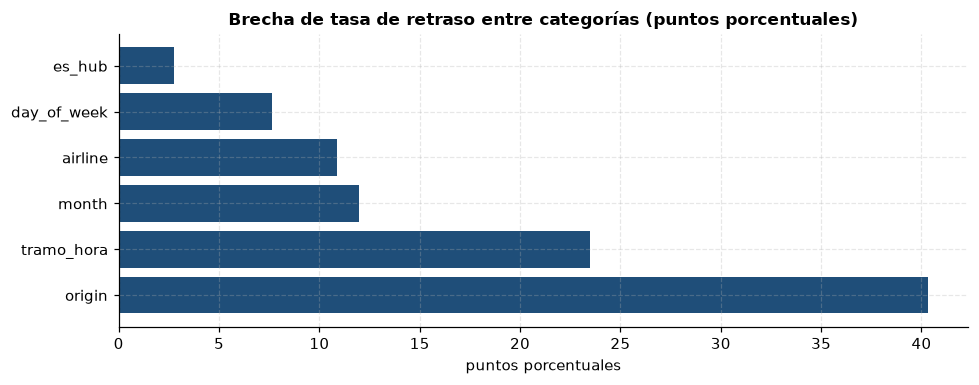

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(señal["variable"], señal["brecha_pp"], color="#1f4e79")
ax.set_title("Brecha de tasa de retraso entre categorías (puntos porcentuales)")
ax.set_xlabel("puntos porcentuales")
g.guardar(fig, "12_senal_categorias.png")
plt.show()

## 3. Señal de las numéricas

Correlación con el objetivo e **información mutua** (mide relación no lineal) sobre una muestra de
200 000 vuelos.

In [5]:
from sklearn.feature_selection import mutual_info_classif

num = ["hora", "salidas_hora", "month", "day_of_week", "distance", "sched_elapsed_time"]
sub = df.sample(200_000, random_state=42).dropna(subset=["arr_del15"])
mi = pd.Series(mutual_info_classif(sub[num], sub.arr_del15, random_state=42), index=num)
corr = df[num + ["arr_del15"]].corr()["arr_del15"].drop("arr_del15")
pd.DataFrame({"correlacion": corr, "info_mutua": mi}).sort_values("info_mutua", ascending=False).round(4)

,correlacion,info_mutua
hora,0.1780,0.0194
day_of_week,0.0272,0.0061
month,0.0256,0.0052
distance,0.0042,0.0035
salidas_hora,0.0433,0.0012
sched_elapsed_time,0.0070,0.0006


## 4. Fuga de información

Si una variable posterior al despegue se usa como predictora, el modelo aprendería el resultado en
lugar de anticiparlo. La correlación con el objetivo lo delata.

In [6]:
post = ["dep_delay", "taxi_out", "air_time", "actual_elapsed_time"]
fuga = df[post].corrwith(df.arr_del15).abs().sort_values(ascending=False)
print(fuga.round(3).to_string())
print(f"\ncausas: el {df.loc[df.carrier_delay.notna(), 'arr_del15'].mean()*100:.0f} % de los vuelos "
      "que las tienen están retrasados (varianza cero: son el resultado, no la causa).")

dep_delay              0.506
taxi_out               0.279
actual_elapsed_time    0.080
air_time               0.027

causas: el 100 % de los vuelos que las tienen están retrasados (varianza cero: son el resultado, no la causa).


## 5. Variable derivada: retraso previo de la matrícula

La causa dominante es la aeronave precedente. Su retraso **sí** se conoce antes de despegar: es el
vuelo anterior de la misma matrícula.

In [7]:
cols = ["tail_number", "flight_date", "hora", "dep_delay", "arr_del15"]
orden = df[cols].sort_values(["tail_number", "flight_date", "hora"])
orden["retraso_previo"] = orden.groupby("tail_number")["dep_delay"].shift()
print(f"cobertura: {orden.retraso_previo.notna().mean()*100:.1f} % de los vuelos")
print(f"correlación con el objetivo: {orden[['retraso_previo','arr_del15']].corr().iloc[0,1]:.3f}")
print(f"tasa de retraso si el vuelo previo llegó tarde: "
      f"{orden.loc[orden.retraso_previo > 15, 'arr_del15'].mean()*100:.1f} % frente a "
      f"{orden.loc[orden.retraso_previo <= 15, 'arr_del15'].mean()*100:.1f} %")

cobertura: 98.3 % de los vuelos


correlación con el objetivo: 0.212


tasa de retraso si el vuelo previo llegó tarde: 46.4 % frente a 16.0 %


## 6. Redundancia

Dos variables que miden lo mismo no se suman: se elige una.

In [8]:
print("distancia ~ duración programada:", round(df[["distance","sched_elapsed_time"]].corr().iloc[0,1], 3))
print("aeropuerto origen ~ estado:", df.groupby("origin", observed=True).origin_state.nunique().max(), "estado por aeropuerto")
print("rutas distintas:", df.groupby(["origin","dest"], observed=True).ngroups)

distancia ~ duración programada: 0.983


aeropuerto origen ~ estado: 1 estado por aeropuerto


rutas distintas: 7344


## 7. Selección final

| Variable | Tipo | Decisión | Motivo |
|---|---|---|---|
| `tramo_hora` | ordinal | **Incluir** | Mayor brecha de tasa (≈28 pp) |
| `origin`, `dest` | categórica | **Incluir** | Brecha ≈15 pp; requieren *target encoding* |
| `month` | ordinal | **Incluir** | Estacionalidad (≈12 pp) |
| `airline` | categórica | **Incluir** | Brecha ≈11 pp |
| `day_of_week` | ordinal | **Incluir** | Brecha ≈8 pp |
| `es_hub` | binaria | **Incluir** | Contexto de congestión |
| `salidas_hora` | numérica | **Incluir** | Proxy de congestión antes del vuelo |
| `retraso_previo` | numérica | **Crear** | Retraso heredado de la rotación (D4) |
| `distance` | numérica | Incluir | Señal débil, pero estable |
| `sched_elapsed_time` | numérica | Excluir | Redundante con `distance` (r = 0,98) |
| `origin_state`, `dest_state` | categórica | Excluir | Redundante con `origin` / `dest` |
| `tail_number` | identificador | Excluir | Sólo se usa para derivar `retraso_previo` |
| `flight_number` | identificador | Excluir | Sin señal |
| `dep_*`, `taxi_*`, `air_time`, `causes` | posteriores | Excluir | Fuga de información |

In [9]:
final = pd.DataFrame([
    ("tramo_hora", "ordinal", "incluir", "brecha ≈28 pp"),
    ("origin", "categórica", "incluir", "brecha ≈15 pp; target encoding"),
    ("dest", "categórica", "incluir", "brecha ≈15 pp; target encoding"),
    ("month", "ordinal", "incluir", "estacionalidad ≈12 pp"),
    ("airline", "categórica", "incluir", "brecha ≈11 pp"),
    ("day_of_week", "ordinal", "incluir", "brecha ≈8 pp"),
    ("es_hub", "binaria", "incluir", "congestión del aeropuerto"),
    ("salidas_hora", "numérica", "incluir", "congestión de la franja"),
    ("retraso_previo", "numérica", "crear", "rotación de la aeronave (D6)"),
    ("distance", "numérica", "incluir", "señal débil pero estable"),
    ("sched_elapsed_time", "numérica", "excluir", "redundante con distance (r=0,98)"),
    ("origin_state", "categórica", "excluir", "redundante con origin"),
    ("dest_state", "categórica", "excluir", "redundante con dest"),
    ("tail_number", "identificador", "excluir", "solo para derivar retraso_previo"),
    ("flight_number", "identificador", "excluir", "sin señal"),
    ("dep_delay", "posterior", "excluir", "fuga de información"),
    ("taxi_out", "posterior", "excluir", "fuga de información"),
    ("air_time", "posterior", "excluir", "fuga de información"),
    ("causas", "posterior", "excluir", "fuga de información"),
], columns=["variable", "tipo", "decision", "motivo"])
final.to_csv(TAB / "03_variables_seleccionadas.csv", index=False, sep=";",
             decimal=",", encoding="utf-8-sig")
print(f"{len(final)} filas → {final.decision.value_counts().to_dict()}")
final

19 filas → {'incluir': 9, 'excluir': 9, 'crear': 1}


,variable,tipo,decision,motivo
0,tramo_hora,ordinal,incluir,brecha ≈28 pp
1,origin,categórica,incluir,brecha ≈15 pp; target encoding
2,dest,categórica,incluir,brecha ≈15 pp; target encoding
3,month,ordinal,incluir,estacionalidad ≈12 pp
4,airline,categórica,incluir,brecha ≈11 pp
5,day_of_week,ordinal,incluir,brecha ≈8 pp
6,es_hub,binaria,incluir,congestión del aeropuerto
7,salidas_hora,numérica,incluir,congestión de la franja
8,retraso_previo,numérica,crear,rotación de la aeronave (D6)
9,distance,numérica,incluir,señal débil pero estable


## 8. Conclusión

- **La hora es la variable más potente** (brecha de 28 pp) y debe entrar por tramos, no como recta.
- **Aeropuerto, mes y aerolínea** aportan entre 8 y 15 pp; el día de la semana, algo menos.
- **La distancia apenas aporta**; se conserva una sola de las dos variables físicas.
- **La rotación de la aeronave** (`retraso_previo`) se puede calcular sin fuga y sustituye a
  `dep_delay`.
- El conjunto final tiene **10 variables** (9 observadas y 1 derivada) y ninguna posterior al
  despegue.

## Dudas y cosas que no nos salieron

- No sabíamos si meter el aeropuerto como 361 columnas de one-hot. Lo probamos y la matriz quedaba
  enorme, así que al final usamos target encoding.
- Al comparar la tasa de retraso por aeropuerto salían valores raros en aeropuertos con pocos
  vuelos, por eso pusimos el mínimo de 1 000.
- Todavía no tenemos claro si usar también el estado del aeropuerto; al final lo quitamos porque el
  aeropuerto ya lo contiene.